

# EAM04DS – Machine Learning
# Energy Consumption Forecasting Using Smart Meter / Building Data
**Hassan Ali Aldhanhani · Student ID 10492852**  
Emirates Aviation University · Fall 2026 · Final project



In [ ]:
import importlib.util, subprocess, sys
packages = {'numpy':'numpy', 'pandas':'pandas', 'matplotlib':'matplotlib',
            'sklearn':'scikit-learn', 'xgboost':'xgboost', 'requests':'requests', 'joblib':'joblib'}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
import os, json, time, hashlib, gzip, base64, io, zipfile, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests, sklearn, xgboost, joblib
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor
SEED = 42
np.random.seed(SEED)
OUT = Path('outputs'); OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False, 'axes.spines.right':False})
versions = {k:v for k,v in [('python',platform.python_version()),('numpy',np.__version__),
 ('pandas',pd.__version__),('sklearn',sklearn.__version__),('xgboost',xgboost.__version__)]}
print(versions)

{'python': '3.12.14', 'numpy': '2.3.5', 'pandas': '2.2.3', 'sklearn': '1.8.0', 'xgboost': '3.4.1'}


## 1. Online source and reproducible acquisition


In [ ]:
SOURCE_URL = 'https://www.kaggle.com/api/v1/datasets/download/jeanmidev/smart-meters-in-london?file_name=halfhourly_dataset%2Fhalfhourly_dataset%2Fblock_0.csv'
SOURCE_SHA256 = 'd43bdc04f50af9711c42917fe257279232ba6a6c0adc55adf6c90899bf6db3d2'
SUBSET_SHA256 = 'a61a2dbc6489fa12f02437e20078e0090aeaee9eef6d961d282f4ed0f4867caf'
HOUSEHOLDS = ['MAC000002', 'MAC000246', 'MAC000450', 'MAC001074', 'MAC003223', 'MAC003239', 'MAC003252', 'MAC003281', 'MAC003305', 'MAC003348']
EMBEDDED_SNAPSHOT = '...'
cache = Path('london_subset.csv.gz')
acquisition = 'verified local snapshot'
if cache.exists() and hashlib.sha256(gzip.decompress(cache.read_bytes())).hexdigest() == SUBSET_SHA256:
    subset_bytes = gzip.decompress(cache.read_bytes())
else:
    try:
        response = requests.get(SOURCE_URL, timeout=90)
        response.raise_for_status()
        archive = zipfile.ZipFile(io.BytesIO(response.content))
        raw_bytes = archive.read('block_0.csv')
        assert hashlib.sha256(raw_bytes).hexdigest() == SOURCE_SHA256, 'Source changed'
        raw = pd.read_csv(io.BytesIO(raw_bytes))
        raw = raw[raw.LCLid.isin(HOUSEHOLDS) & raw.tstp.str.startswith('2013')]
        subset_bytes = raw.to_csv(index=False).encode()
        assert hashlib.sha256(subset_bytes).hexdigest() == SUBSET_SHA256
        acquisition = 'downloaded from Kaggle public online endpoint'
    except (requests.RequestException, zipfile.BadZipFile, KeyError, AssertionError) as exc:
        print('Download unavailable or source changed:', type(exc).__name__)
        subset_bytes = gzip.decompress(base64.b64decode(EMBEDDED_SNAPSHOT))
        acquisition = 'embedded exact online-derived snapshot'
    cache.write_bytes(gzip.compress(subset_bytes, mtime=0))
assert hashlib.sha256(subset_bytes).hexdigest() == SUBSET_SHA256
raw = pd.read_csv(io.BytesIO(subset_bytes))
print(acquisition, '\nRows:',len(raw),'Households:',raw.LCLid.nunique())
display(raw.head())
manifest = dict(source_url=SOURCE_URL, source_sha256=SOURCE_SHA256, subset_sha256=SUBSET_SHA256,
                households=HOUSEHOLDS, period='2013', seed=SEED, versions=versions)
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2))

verified local snapshot 
Rows: 146583 Households: 9
Out[2]: 704


,LCLid,tstp,energy(kWh/hh)
0,MAC000002,2013-01-01 00:00:00.0000000,0.219
1,MAC000002,2013-01-01 00:30:00.0000000,0.241
2,MAC000002,2013-01-01 01:00:00.0000000,0.191
3,MAC000002,2013-01-01 01:30:00.0000000,0.235
4,MAC000002,2013-01-01 02:00:00.0000000,0.182


## 2. Data quality and time grid


,count
raw_rows,146583
invalid_timestamps,0
missing_or_invalid_energy,0
negative_energy,0
duplicate_keys,0
grid_rows,175200
missing_on_grid,28617


,count,mean,std,max
LCLid,,,,
MAC000002,17520,0.2406,0.2397,2.994
MAC000246,17518,0.3929,0.4712,3.516
MAC000450,6431,1.4671,0.6490,4.385
MAC001074,0,NaN,NaN,NaN
MAC003223,17519,0.3826,0.3903,4.404
MAC003239,17519,0.1465,0.1173,1.357
MAC003252,17519,0.2650,0.2737,2.888
MAC003281,17518,0.2093,0.2576,2.782
MAC003305,17520,0.3229,0.2483,2.230


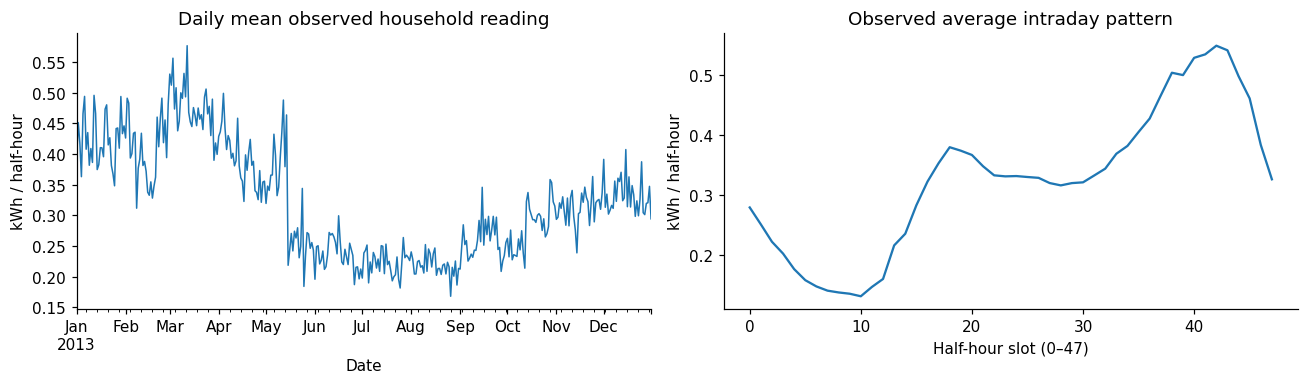

In [ ]:
raw['timestamp'] = pd.to_datetime(raw['tstp'], errors='coerce')
raw['y'] = pd.to_numeric(raw['energy(kWh/hh)'], errors='coerce')
audit = {'raw_rows':len(raw), 'invalid_timestamps':int(raw.timestamp.isna().sum()),
         'missing_or_invalid_energy':int(raw.y.isna().sum()), 'negative_energy':int((raw.y<0).sum()),
         'duplicate_keys':int(raw.duplicated(['LCLid','timestamp']).sum())}
raw.loc[raw.y<0,'y'] = np.nan
clean = raw.dropna(subset=['timestamp']).groupby(['LCLid','timestamp'],as_index=False)['y'].mean()
grid = pd.date_range('2013-01-01','2013-12-31 23:30',freq='30min')
parts=[]
for hid in HOUSEHOLDS:
    s=clean[clean.LCLid==hid].set_index('timestamp')['y'].reindex(grid)
    parts.append(pd.DataFrame({'timestamp':grid,'LCLid':hid,'y':s.to_numpy()}))
panel=pd.concat(parts,ignore_index=True)
audit.update(grid_rows=len(panel), missing_on_grid=int(panel.y.isna().sum()))
display(pd.Series(audit,name='count').to_frame())
display(panel.groupby('LCLid').y.agg(['count','mean','std','max']).round(4))
(OUT/'data_audit.json').write_text(json.dumps(audit,indent=2))
fig,axs=plt.subplots(1,2,figsize=(12,3.6))
panel.assign(day=panel.timestamp.dt.floor('D')).groupby('day').y.mean().plot(ax=axs[0],lw=1)
axs[0].set(title='Daily mean observed household reading',ylabel='kWh / half-hour',xlabel='Date')
panel.assign(slot=panel.timestamp.dt.hour*2+panel.timestamp.dt.minute//30).groupby('slot').y.mean().plot(ax=axs[1])
axs[1].set(title='Observed average intraday pattern',ylabel='kWh / half-hour',xlabel='Half-hour slot (0–47)')
plt.tight_layout();plt.savefig(OUT/'eda.png');plt.show()

## 3. Features and leakage safeguards


In [ ]:
def build_features(frame):
    frame=frame.sort_values(['LCLid','timestamp']).copy()
    g=frame.groupby('LCLid',sort=False)['y']
    for lag in (1,2,48,336): frame[f'lag_{lag}']=g.shift(lag)
    for window in (48,336):
        frame[f'roll_mean_{window}']=g.transform(lambda s:s.shift(1).rolling(window,min_periods=window).mean())
        frame[f'roll_std_{window}']=g.transform(lambda s:s.shift(1).rolling(window,min_periods=window).std())
    slot=frame.timestamp.dt.hour*2+frame.timestamp.dt.minute//30
    dow=frame.timestamp.dt.dayofweek
    frame['slot_sin']=np.sin(2*np.pi*slot/48);frame['slot_cos']=np.cos(2*np.pi*slot/48)
    frame['dow_sin']=np.sin(2*np.pi*dow/7);frame['dow_cos']=np.cos(2*np.pi*dow/7)
    frame['weekend']=(dow>=5).astype(int)
    frame['year_sin']=np.sin(2*np.pi*frame.timestamp.dt.dayofyear/365.25)
    frame['year_cos']=np.cos(2*np.pi*frame.timestamp.dt.dayofyear/365.25)
    return frame
featured=build_features(panel)
numeric=[c for c in featured if c not in ['LCLid','timestamp','y']]
features=['LCLid']+numeric
probe=panel[panel.LCLid==HOUSEHOLDS[0]].iloc[:800].copy()
changed=probe.copy();changed.loc[changed.index[600:],'y']=9999
pd.testing.assert_series_equal(build_features(probe).iloc[600][features],
                               build_features(changed).iloc[600][features])
assert np.isclose(featured.loc[1,'lag_1'],panel.loc[0,'y'],equal_nan=True)
df=featured.dropna(subset=['y']+numeric).sort_values(['timestamp','LCLid']).reset_index(drop=True)
audit['usable_rows']=len(df);audit['excluded_grid_rows']=len(panel)-len(df)
(OUT/'data_audit.json').write_text(json.dumps(audit,indent=2))
print('Causality checks passed. Complete-history rows:',len(df),'of',len(panel))
folds=[('July','2013-07-01','2013-08-01'),('August','2013-08-01','2013-09-01')]
train=df[df.timestamp<'2013-09-01'].copy()
test=df[df.timestamp>='2013-09-01'].copy()
assert train.timestamp.max()<test.timestamp.min()
assert not train.duplicated(['LCLid','timestamp']).any()
splits=[]
for name,start,end in folds:
    a=df[df.timestamp<start];b=df[(df.timestamp>=start)&(df.timestamp<end)]
    assert a.timestamp.max()<b.timestamp.min()
    splits.append({'split':name+' training','rows':len(a),'start':str(a.timestamp.min()),'end':str(a.timestamp.max())})
    splits.append({'split':name+' validation','rows':len(b),'start':str(b.timestamp.min()),'end':str(b.timestamp.max())})
splits.extend([{'split':'Final training','rows':len(train),'start':str(train.timestamp.min()),'end':str(train.timestamp.max())},
               {'split':'Untouched test','rows':len(test),'start':str(test.timestamp.min()),'end':str(test.timestamp.max())}])
splits=pd.DataFrame(splits);display(splits);splits.to_csv(OUT/'splits.csv',index=False)

Causality checks passed. Complete-history rows: 140199 of 175200


,split,rows,start,end
0,July training,70554,2013-01-08 00:00:00,2013-06-30 23:30:00
1,July validation,11904,2013-07-01 00:00:00,2013-07-31 23:30:00
2,August training,82458,2013-01-08 00:00:00,2013-07-31 23:30:00
3,August validation,11761,2013-08-01 00:00:00,2013-08-31 23:30:00
4,Final training,94219,2013-01-08 00:00:00,2013-08-31 23:30:00
5,Untouched test,45980,2013-09-01 00:00:00,2013-12-31 23:30:00


## 4. Models and expanding-window validation


In [ ]:
def metrics(y,p):
    return {'MAE':mean_absolute_error(y,p),'RMSE':np.sqrt(mean_squared_error(y,p)),'R2':r2_score(y,p)}
def make_pipeline(model,cols=numeric):
    prep=ColumnTransformer([('num',StandardScaler(),cols),
        ('id',OneHotEncoder(handle_unknown='ignore',sparse_output=False),['LCLid'])])
    return Pipeline([('prepare',prep),('model',model)])
candidates={
 'Linear Regression':[{}],
 'Random Forest':[{'n_estimators':60,'max_depth':12,'min_samples_leaf':5,'max_features':0.8},
                  {'n_estimators':60,'max_depth':16,'min_samples_leaf':10,'max_features':0.8}],
 'XGBoost':[{'n_estimators':180,'max_depth':3,'learning_rate':0.06},
            {'n_estimators':180,'max_depth':5,'learning_rate':0.06}]}
def estimator(name,params):
    if name=='Linear Regression': return LinearRegression()
    if name=='Random Forest': return RandomForestRegressor(random_state=SEED,n_jobs=2,**params)
    return XGBRegressor(objective='reg:squarederror',tree_method='hist',random_state=SEED,
           n_jobs=2,subsample=0.9,colsample_bytree=0.9,reg_lambda=1.0,**params)
validation=[]
for name,grid_params in candidates.items():
    for ci,params in enumerate(grid_params):
        for fold,start,end in folds:
            a=df[df.timestamp<start];b=df[(df.timestamp>=start)&(df.timestamp<end)]
            model=make_pipeline(estimator(name,params))
            t0=time.perf_counter();model.fit(a[features],a.y)
            p=np.maximum(0,model.predict(b[features]))
            validation.append(dict(model=name,candidate=ci,fold=fold,seconds=time.perf_counter()-t0,**metrics(b.y,p)))
        print('Validated',name,ci,flush=True)
cv=pd.DataFrame(validation)
cv_summary=cv.groupby(['model','candidate'],as_index=False)[['MAE','RMSE','R2','seconds']].mean()
chosen=cv_summary.loc[cv_summary.groupby('model').RMSE.idxmin()].sort_values('RMSE')
chosen_params={r.model:candidates[r.model][int(r.candidate)] for r in chosen.itertuples()}
preferred=chosen.iloc[0]['model']
display(cv_summary.round(5));print('Selected by validation:',preferred)
cv.to_csv(OUT/'validation_folds.csv',index=False)
(OUT/'selected_parameters.json').write_text(json.dumps(chosen_params,indent=2))

Validated Linear Regression 0
Validated Random Forest 0
Validated Random Forest 1
Validated XGBoost 0
Validated XGBoost 1
Selected by validation: Random Forest
Out[5]: 243


,model,candidate,MAE,RMSE,R2,seconds
0,Linear Regression,0,0.08990,0.16669,0.45595,0.14853
1,Random Forest,0,0.08694,0.16137,0.48999,13.48125
2,Random Forest,1,0.08574,0.16084,0.49334,16.18103
3,XGBoost,0,0.08803,0.16360,0.47592,0.56658
4,XGBoost,1,0.08911,0.16316,0.47852,0.75401


## 5. Locked test evaluation


,model,MAE,RMSE,R2,RMSE_skill_vs_persistence,fit_seconds
5,XGBoost,0.11098,0.20256,0.58476,0.14843,0.87682
4,Random Forest,0.11129,0.20303,0.58283,0.14646,19.79228
6,Linear Regression,0.11636,0.21065,0.55093,0.11443,0.09709
1,Persistence,0.12292,0.23787,0.42738,0.00000,0.00000
0,Training mean,0.22886,0.31654,-0.01402,-0.33073,0.00000
3,Weekly naive,0.18614,0.33430,-0.13101,-0.40540,0.00000
2,Daily naive,0.18168,0.33684,-0.14825,-0.41607,0.00000


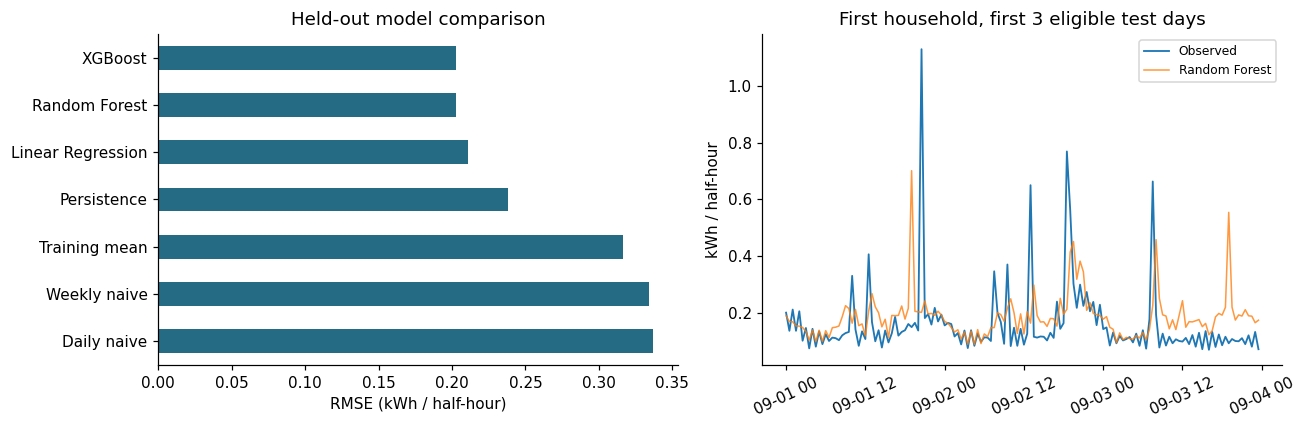

In [ ]:
predictions=test[['timestamp','LCLid','y']].copy()
predictions['Training mean']=train.y.mean()
predictions['Persistence']=test.lag_1.to_numpy()
predictions['Daily naive']=test.lag_48.to_numpy()
predictions['Weekly naive']=test.lag_336.to_numpy()
fitted={};fit_times={}
for name,params in chosen_params.items():
    model=make_pipeline(estimator(name,params));t0=time.perf_counter()
    model.fit(train[features],train.y);fit_times[name]=time.perf_counter()-t0
    predictions[name]=np.maximum(0,model.predict(test[features]));fitted[name]=model
results=pd.DataFrame([dict(model=name,**metrics(predictions.y,predictions[name]))
                     for name in predictions.columns[3:]]).sort_values('RMSE')
persist_rmse=results.set_index('model').loc['Persistence','RMSE']
results['RMSE_skill_vs_persistence']=1-results.RMSE/persist_rmse
results['fit_seconds']=results.model.map(fit_times).fillna(0)
display(results.round(5));results.to_csv(OUT/'test_metrics.csv',index=False)
predictions.to_csv(OUT/'test_predictions.csv.gz',index=False,compression='gzip')
fig,axs=plt.subplots(1,2,figsize=(12,4))
results.plot.barh(x='model',y='RMSE',legend=False,ax=axs[0],color='#246b83');axs[0].invert_yaxis()
axs[0].set(xlabel='RMSE (kWh / half-hour)',ylabel='',title='Held-out model comparison')
example=predictions[predictions.LCLid==HOUSEHOLDS[0]].iloc[:144]
axs[1].plot(example.timestamp,example.y,label='Observed',lw=1.2)
axs[1].plot(example.timestamp,example[preferred],label=preferred,lw=1,alpha=.8)
axs[1].set(title='First household, first 3 eligible test days',ylabel='kWh / half-hour')
axs[1].tick_params(axis='x',rotation=25);axs[1].legend(fontsize=8)
plt.tight_layout();plt.savefig(OUT/'results.png');plt.show()

## 6. Robustness, peak demand and uncertainty


{'model': 'Random Forest', 'daily_mean_MAE_difference': -0.011630344998651366, '95pct_low': -0.013199150701103519, '95pct_high': -0.01020891293734243, 'block_days': 7, 'replicates': 2000}


,household,rows,MAE,RMSE,R2
0,MAC000002,5856,0.09461,0.17058,0.52638
1,MAC000246,5519,0.17884,0.28811,0.62005
2,MAC003223,5519,0.17612,0.30115,0.43798
3,MAC003239,5662,0.05016,0.07834,0.59969
4,MAC003252,5856,0.10554,0.19582,0.43915
5,MAC003281,5856,0.10098,0.16950,0.61072
6,MAC003305,5856,0.09264,0.16207,0.65090
7,MAC003348,5856,0.09700,0.17769,0.55472


,month,rows,MAE,RMSE,R2
0,2013-09,11326,0.10111,0.18578,0.55564
1,2013-10,11904,0.10878,0.20208,0.58224
2,2013-11,11520,0.11740,0.21208,0.57033
3,2013-12,11230,0.11793,0.21103,0.60452


,segment,rows,MAE,RMSE,R2
0,non-peak,39524,0.08000,0.12731,0.37560
1,peak,6456,0.30285,0.44086,-0.02679


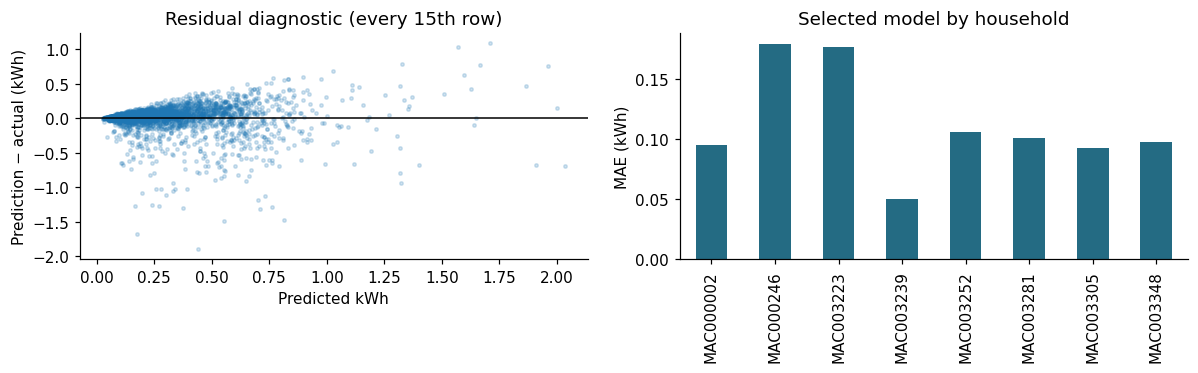

In [ ]:
diagnostics=predictions.copy()
diagnostics['error']=diagnostics[preferred]-diagnostics.y
diagnostics['absolute_error']=diagnostics.error.abs()
thresholds=train.groupby('LCLid').y.quantile(.9)
diagnostics['peak']=diagnostics.y>diagnostics.LCLid.map(thresholds)
household=pd.DataFrame([dict(household=h,rows=len(g),**metrics(g.y,g[preferred]))
                        for h,g in diagnostics.groupby('LCLid')])
monthly=pd.DataFrame([dict(month=str(m),rows=len(g),**metrics(g.y,g[preferred]))
                      for m,g in diagnostics.groupby(diagnostics.timestamp.dt.to_period('M'))])
peak=pd.DataFrame([dict(segment='peak' if key else 'non-peak',rows=len(g),**metrics(g.y,g[preferred]))
                   for key,g in diagnostics.groupby('peak')])
display(household.round(5));display(monthly.round(5));display(peak.round(5))
for name,table in [('household_metrics',household),('monthly_metrics',monthly),('peak_metrics',peak)]:
    table.to_csv(OUT/(name+'.csv'),index=False)
diagnostics['paired_difference']=diagnostics.absolute_error-(diagnostics.Persistence-diagnostics.y).abs()
daily=diagnostics.groupby(diagnostics.timestamp.dt.floor('D')).paired_difference.mean()
assert daily.index.to_series().diff().dropna().eq(pd.Timedelta(days=1)).all()
values=daily.to_numpy();rng=np.random.default_rng(SEED);L=7;B=2000
boot=[]
for _ in range(B):
    starts=rng.integers(0,len(values)-L+1,size=int(np.ceil(len(values)/L)))
    sample=np.concatenate([values[s:s+L] for s in starts])[:len(values)]
    boot.append(sample.mean())
ci=np.quantile(boot,[.025,.975])
uncertainty={'model':preferred,'daily_mean_MAE_difference':float(values.mean()),
             '95pct_low':float(ci[0]),'95pct_high':float(ci[1]),'block_days':L,'replicates':B}
print(uncertainty);(OUT/'uncertainty.json').write_text(json.dumps(uncertainty,indent=2))
fig,axs=plt.subplots(1,2,figsize=(11,3.5))
axs[0].scatter(diagnostics[preferred].iloc[::15],diagnostics.error.iloc[::15],s=5,alpha=.2)
axs[0].axhline(0,color='black',lw=1);axs[0].set(xlabel='Predicted kWh',ylabel='Prediction − actual (kWh)',title='Residual diagnostic (every 15th row)')
household.plot.bar(x='household',y='MAE',legend=False,ax=axs[1],color='#246b83');axs[1].set(title='Selected model by household',ylabel='MAE (kWh)',xlabel='')
plt.tight_layout();plt.savefig(OUT/'diagnostics.png');plt.show()

## 7. Lag ablation and feature interpretation


,features,MAE,RMSE,R2
0,Calendar + ID only,0.16034,0.26812,0.27246
1,History + calendar + ID,0.11098,0.20256,0.58476


,feature,MAE_increase,repeat_std
1,lag_1,0.11739,0.00153
3,lag_48,0.00749,0.00048
4,lag_336,0.00599,0.00026
2,lag_2,0.00506,0.00004
9,slot_sin,0.00431,0.00020
10,slot_cos,0.00353,0.00033
0,LCLid,0.00349,0.00037
8,roll_std_336,0.00278,0.00010
5,roll_mean_48,0.00274,0.00042
7,roll_mean_336,0.00171,0.00010


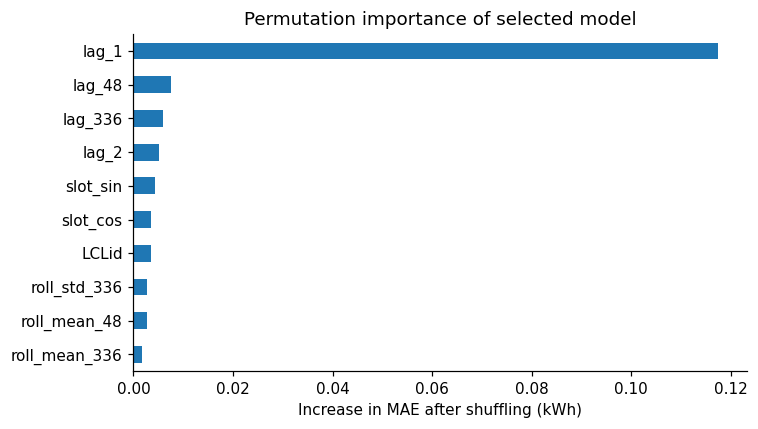

In [ ]:
calendar=[c for c in numeric if not c.startswith(('lag_','roll_'))]
ablation_model=make_pipeline(estimator('XGBoost',chosen_params['XGBoost']),calendar)
ablation_model.fit(train[features],train.y)
ablation_pred=np.maximum(0,ablation_model.predict(test[features]))
ablation=pd.DataFrame([dict(features='Calendar + ID only',**metrics(test.y,ablation_pred)),
                        dict(features='History + calendar + ID',**metrics(test.y,predictions['XGBoost']))])
display(ablation.round(5));ablation.to_csv(OUT/'ablation.csv',index=False)
ix=np.random.default_rng(SEED).choice(len(test),size=min(3000,len(test)),replace=False)
importance=permutation_importance(fitted[preferred],test.iloc[ix][features],test.iloc[ix].y,
           scoring='neg_mean_absolute_error',n_repeats=3,random_state=SEED,n_jobs=1)
imp=pd.DataFrame({'feature':features,'MAE_increase':importance.importances_mean,
                  'repeat_std':importance.importances_std}).sort_values('MAE_increase',ascending=False)
display(imp.round(5));imp.to_csv(OUT/'permutation_importance.csv',index=False)
imp.head(10).sort_values('MAE_increase').plot.barh(x='feature',y='MAE_increase',legend=False,figsize=(7,4))
plt.xlabel('Increase in MAE after shuffling (kWh)');plt.ylabel('');plt.title('Permutation importance of selected model')
plt.tight_layout();plt.savefig(OUT/'importance.png');plt.show()

## 8. Save the model and demonstrate inference


In [ ]:
bundle={'pipeline':fitted[preferred],'features':features,'model_name':preferred,
        'forecast_horizon_minutes':30,'manifest':manifest}
joblib.dump(bundle,OUT/'selected_model.joblib',compress=3)
loaded=joblib.load(OUT/'selected_model.joblib')
single=test.iloc[[0]]
one_prediction=float(np.maximum(0,loaded['pipeline'].predict(single[loaded['features']]))[0])
assert np.isclose(one_prediction,predictions.iloc[0][preferred])
print({'household':single.LCLid.iloc[0],'target_time':str(single.timestamp.iloc[0]),
       'predicted_kWh':one_prediction,'observed_kWh':float(single.y.iloc[0])})
assert np.isfinite(results[['MAE','RMSE','R2']].to_numpy()).all()
assert all(np.isfinite(predictions[c]).all() for c in predictions.columns[3:])
print('All data, chronology, causality, finite-output and save/reload checks passed.')

{'household': 'MAC000002', 'target_time': '2013-09-01 00:00:00', 'predicted_kWh': 0.18884805802891466, 'observed_kWh': 0.2}
All data, chronology, causality, finite-output and save/reload checks passed.


## 9. Interpretation of the executed experiment

In [ ]:
selected_row=results.set_index('model').loc[preferred]
best_test=results.iloc[0]['model']
text=f"""The validation-selected model is **{preferred}**. On {len(test):,} held-out household readings it obtains
MAE **{selected_row.MAE:.5f} kWh**, RMSE **{selected_row.RMSE:.5f} kWh** and R² **{selected_row.R2:.4f}**.
Its RMSE improvement over persistence is **{100*selected_row.RMSE_skill_vs_persistence:.2f}%**.
The lowest test RMSE is achieved by **{best_test}**; this retrospective ranking does not replace validation selection.
The 95% seven-day block-bootstrap interval for daily mean paired MAE difference is
**[{ci[0]:.5f}, {ci[1]:.5f}] kWh**. An interval spanning zero does not establish a clear difference.
Calendar-only XGBoost RMSE is **{ablation.iloc[0].RMSE:.5f}**, compared with **{ablation.iloc[1].RMSE:.5f}** using history.
These figures describe the fixed ten-household cohort, not city-wide accuracy."""
display(Markdown(text));(OUT/'findings.md').write_text(text)
summary={'preferred':preferred,'test_rows':len(test),'train_rows':len(train),
         'results':results.to_dict('records'),'uncertainty':uncertainty,
         'ablation':ablation.to_dict('records'),'audit':audit}
(OUT/'summary.json').write_text(json.dumps(summary,indent=2))

Out[10]: 2550


The validation-selected model is **Random Forest**. On 45,980 held-out household readings it obtains
MAE **0.11129 kWh**, RMSE **0.20303 kWh** and R² **0.5828**.
Its RMSE improvement over persistence is **14.65%**.
The lowest test RMSE is achieved by **XGBoost**; this retrospective ranking does not replace validation selection.
The 95% seven-day block-bootstrap interval for daily mean paired MAE difference is
**[-0.01320, -0.01021] kWh**. An interval spanning zero does not establish a clear difference.
Calendar-only XGBoost RMSE is **0.26812**, compared with **0.20256** using history.
These figures describe the fixed ten-household cohort, not city-wide accuracy.